In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import anndata as ad
import h5py

In [2]:
atlas_path = "/g/arendt/gerber/Analyses/Axolotl/PlatyAtlas.h5ad"

In [3]:
atlas = sc.read_h5ad(atlas_path)

In [4]:
atlas

AnnData object with n_obs × n_vars = 99775 × 64955
    obs: 'cell_name', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'RNA_snn_res.0.6', 'seurat_clusters', 'RNA_snn_res.1', 'RNA_snn_res.0.8', 'S.Score', 'G2M.Score', 'Phase', 'nj_clusters', 'clade_clusters', 'nj_clusters.longer', 'clade_clusters.longer', 'clade_coarse_nj', 'curated_48hpf.derived_annotations'
    var: 'features'
    obsm: 'X_harmony', 'X_pca', 'X_umap'
    varm: 'HARMONY', 'PCs'

In [5]:
atlas.var

,features
XLOC-000001,XLOC-000001
XLOC-000002,XLOC-000002
XLOC-000003,XLOC-000003
XLOC-000004,XLOC-000004
XLOC-000005,XLOC-000005
...,...
XLOC-062744,XLOC-062744
XLOC-065137,XLOC-065137
XLOC-067433,XLOC-067433
XLOC-068640,XLOC-068640


In [5]:
ncald_expr = atlas[:, "XLOC-040379"].X.toarray().T[0]

In [6]:
ncald_expr

array([0., 0., 0., ..., 0., 0., 0.])

(array([9.1775e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+01, 2.8000e+01,
        3.4000e+01, 3.1000e+01, 4.5000e+01, 5.3000e+01, 4.8000e+01,
        5.7000e+01, 7.0000e+01, 8.2000e+01, 8.2000e+01, 8.5000e+01,
        1.1800e+02, 1.3000e+02, 1.2100e+02, 1.3700e+02, 1.4400e+02,
        1.8700e+02, 1.8000e+02, 1.9000e+02, 1.9700e+02, 2.1700e+02,
        2.5500e+02, 2.3300e+02, 2.5000e+02, 2.3100e+02, 2.6200e+02,
        2.5600e+02, 2.7600e+02, 2.6500e+02, 2.4700e+02, 2.6400e+02,
        2.5300e+02, 2.2200e+02, 2.1600e+02, 1.9200e+02, 1.8000e+02,
        1.7000e+02, 1.5000e+02, 1.5500e+02, 1.4700e+02, 1.4000e+02,
        1.2100e+02, 1.1900e+02, 1.0700e+02, 1.1700e+02, 9.1000e+01,
        8.4000e+01, 7.6000e+01, 5.5000e+01, 5.8000e+01, 6.5000e+01,
        5.3000e+01, 3.9000e+01, 4.9000e+01, 3.6000e+01, 3.7000e+01,
        3.7000e+01, 4.0000e+01, 3.0000e+01, 2.00

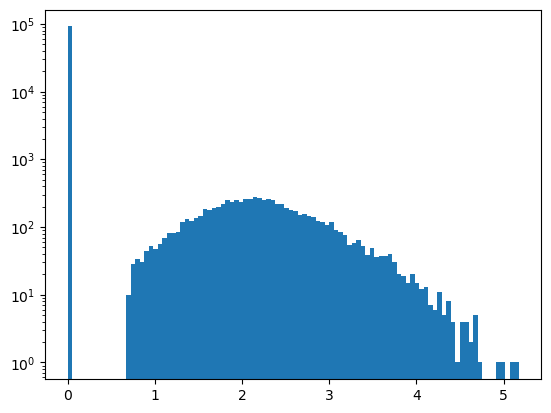

In [7]:
plt.hist(ncald_expr, bins=100, log=True)

In [8]:
ncald_expr_sorted = np.sort(ncald_expr)

In [9]:
ncald_expr_sorted

array([0.        , 0.        , 0.        , ..., 4.96704903, 5.10148284,
       5.17188324])

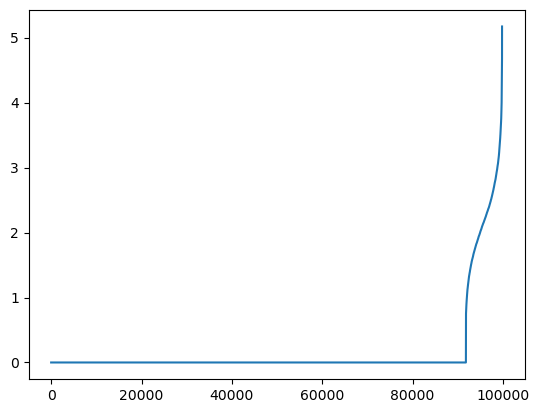

In [10]:
plt.plot(ncald_expr_sorted)

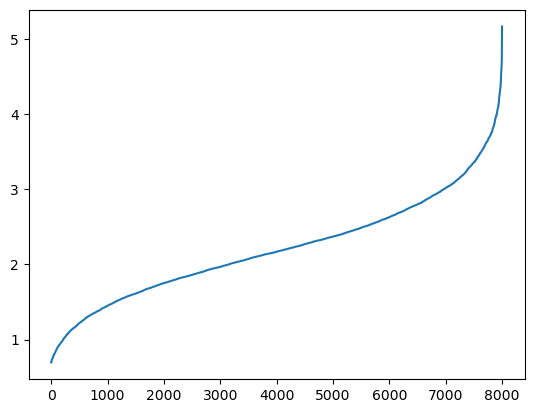

In [11]:
plt.plot(ncald_expr_sorted[ncald_expr_sorted > 0])

In [12]:
ptf1_expr = atlas[:, "XLOC-003959"].X.toarray().T[0]

In [13]:
ptf1_expr_sorted = np.sort(ptf1_expr)

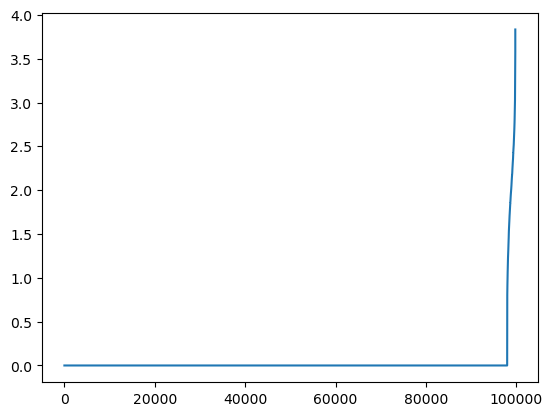

In [14]:
plt.plot(ptf1_expr_sorted)

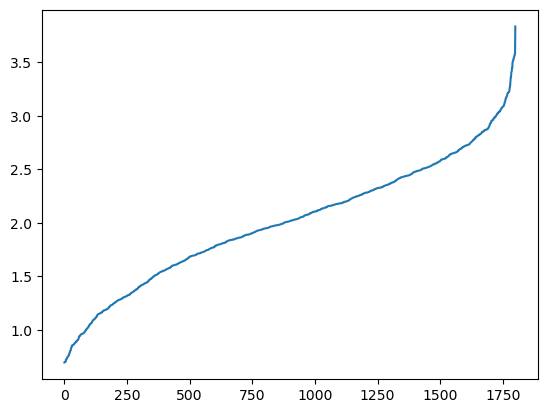

In [15]:
plt.plot(ptf1_expr_sorted[ptf1_expr_sorted > 0])

In [45]:
gene_dict = {"Arx": "XLOC-044659", 
             "Ptf1": "XLOC-003959", 
             "NCALD": "XLOC-040379", 
             "Pkd1": "XLOC-027897",
             "ROpsin1": "XLOC-028295",
             "Brn3": "XLOC-000129",
             "COpsin": "XLOC-012133"}

gene_dict = {"Arx": "XLOC-044659", 
             "Ptf1": "XLOC-003959", 
             "NCALD": "XLOC-040379", 
             "Pkd1": "XLOC-027897",
             "Brn3": "XLOC-000129"}


gene_list = gene_dict.keys()
id_list = [gene_dict[key] for key in gene_list]

Text(0.5, 0, 'Cell number')

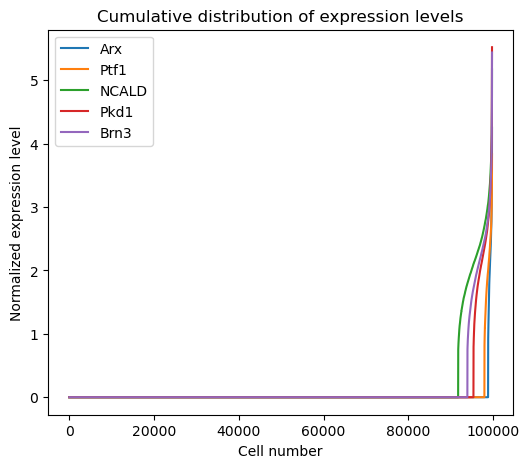

In [46]:
plt.figure(figsize=(6, 5))
for name, idx in zip(gene_list, id_list):
    expr = atlas[:, idx].X.toarray().T[0]
    expr_sorted = np.sort(expr)
    plt.plot(expr_sorted, label=name)
    # plt.hist(expr, 100, cumulative=True, label=name, histtype="step", orientation="horisontal")
plt.legend()
plt.title("Cumulative distribution of expression levels")
plt.ylabel("Normalized expression level")
plt.xlabel("Cell number")

In [47]:
atlas_subset = atlas[:, id_list]

In [48]:
cluster_ids = atlas_subset.obs["seurat_clusters"].unique()
cluster_ids.sort()

In [49]:
cluster_ids

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64],
      dtype=int32)

In [50]:
cluster_prob = np.array(atlas_subset.obs["seurat_clusters"].value_counts() / len(atlas_subset.obs["seurat_clusters"]))

In [51]:
nonzero_cluster = []
cluster_prob = []
N = len(atlas_subset.obs)
for cluster_id in cluster_ids:
    atlas_cluster = atlas_subset[atlas_subset.obs["seurat_clusters"] == cluster_id, :]
    cluster_size = len(atlas_cluster.obs)
    cluster_prob.append(cluster_size / N)
    nonzero_cluster.append((atlas_cluster.X > 2).sum(axis=0) / cluster_size)
    
cluster_prob = np.array(cluster_prob)[None, :]
nonzero_cluster = np.array(nonzero_cluster).squeeze().T

In [52]:
cluster_prob.shape

(1, 65)

In [53]:
nonzero_cluster.shape

(5, 65)

In [54]:
gene_list

dict_keys(['Arx', 'Ptf1', 'NCALD', 'Pkd1', 'Brn3'])

Text(0, 0.5, 'Normalized cluster size')

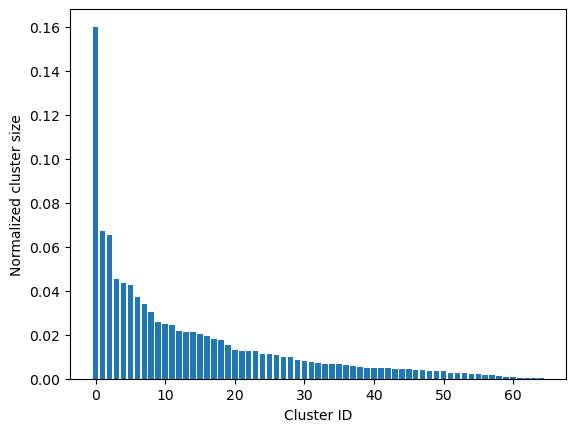

In [55]:
plt.bar(cluster_ids, cluster_prob.squeeze())
plt.xlabel("Cluster ID")
plt.ylabel("Normalized cluster size")

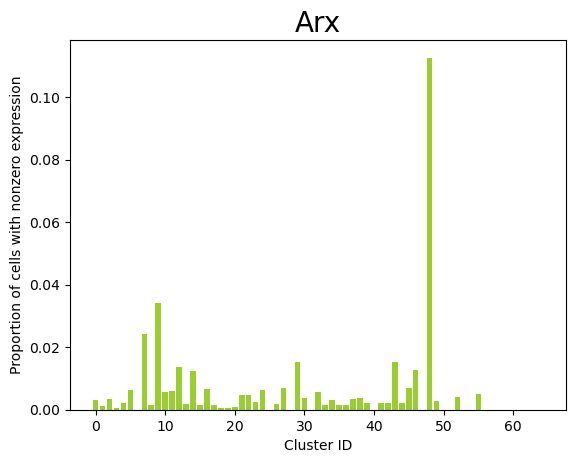

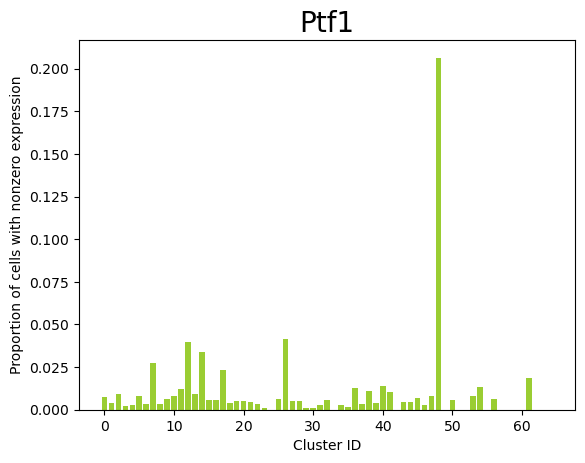

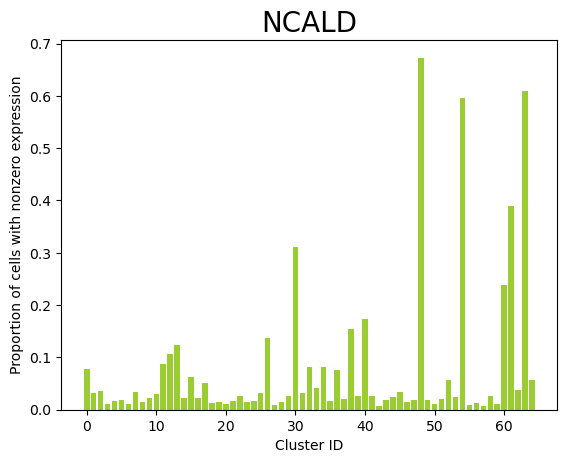

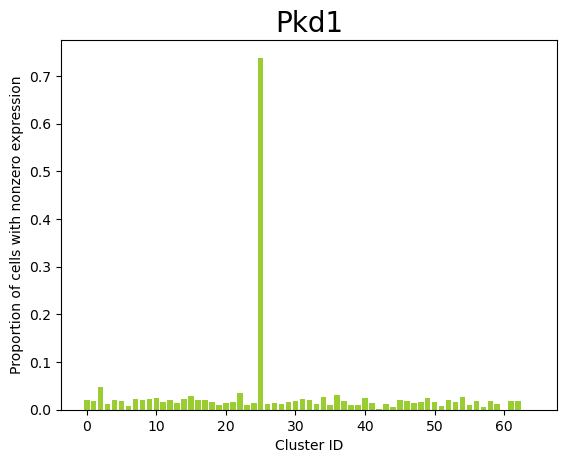

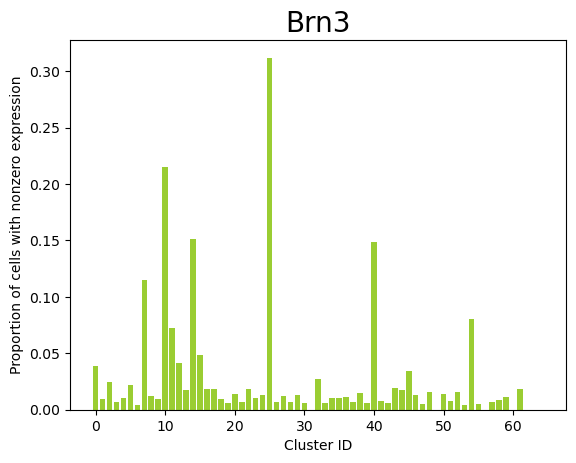

In [56]:
for idx, name in enumerate(gene_list):
    plt.figure()
    plt.bar(cluster_ids, nonzero_cluster[idx, :], color="yellowgreen")
    plt.xlabel("Cluster ID")
    plt.ylabel("Proportion of cells with nonzero expression")
    plt.title(name, fontsize=20)

In [57]:
def expr_to_cluster_probability(e, cluster_prob, nonzero_cluster):
    nonzero_total = nonzero_cluster.sum(axis=1, keepdims=True)
    expressed_prob = np.prod(nonzero_cluster[e.squeeze() > 0, :], axis=0)
    nonexpressed_prob = np.prod((1 - nonzero_cluster)[(1 - e).squeeze() > 0, :], axis=0)
    e_prob = expressed_prob * nonexpressed_prob
    nominator = e_prob * cluster_prob
    denominator = np.dot(e, nonzero_total)
    return e_prob, nominator / denominator

In [58]:
gene_list

dict_keys(['Arx', 'Ptf1', 'NCALD', 'Pkd1', 'Brn3'])

In [89]:
e = np.array([0, 0, 1, 0, 0])[None, :]

In [90]:
e.shape

(1, 5)

In [91]:
nonzero_cluster.sum(axis=1).shape

(5,)

In [92]:
e_prob, ropsin_prob = expr_to_cluster_probability(e, cluster_prob, nonzero_cluster)

In [93]:
ropsin_prob.sum()

0.008736647007958858

In [94]:
ropsin_prob.shape

(1, 65)

<BarContainer object of 65 artists>

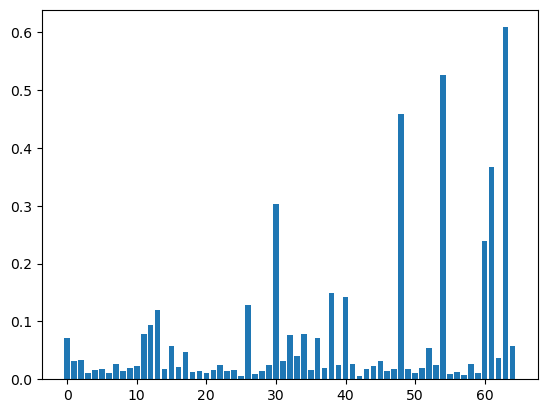

In [95]:
plt.bar(cluster_ids, e_prob.squeeze())

Text(0, 0.5, 'Probability of each cluster')

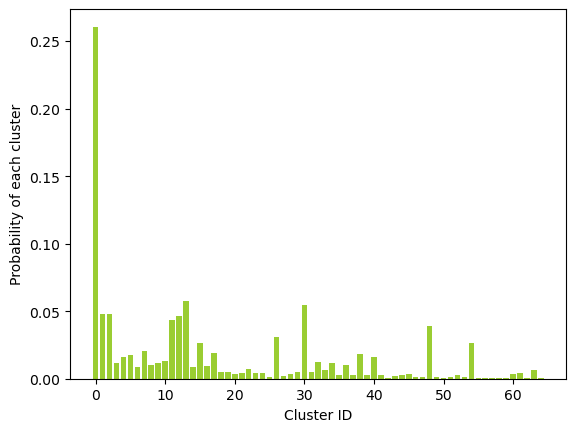

In [96]:
plt.bar(cluster_ids, ropsin_prob.squeeze() / ropsin_prob.sum(), color="yellowgreen")
plt.xlabel("Cluster ID")
plt.ylabel("Probability of each cluster")

<BarContainer object of 65 artists>

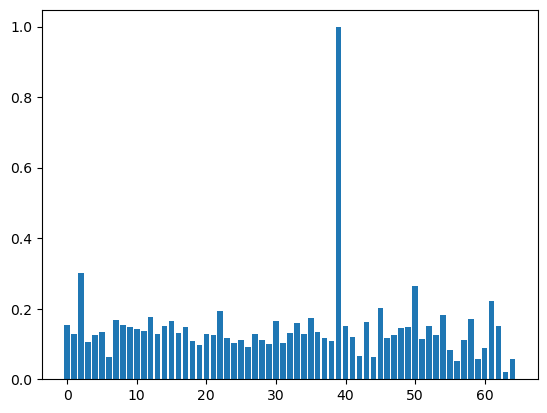

In [142]:
plt.bar(cluster_ids, nonzero_cluster[4, :])

<BarContainer object of 65 artists>

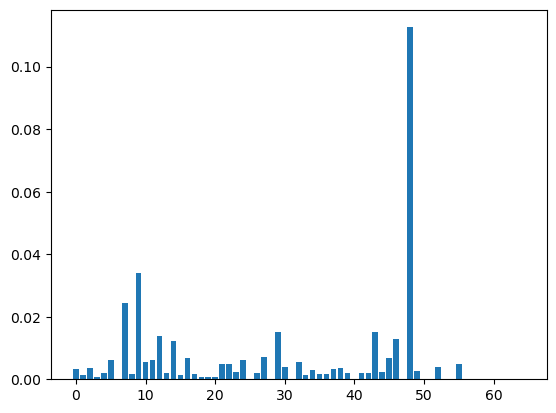

In [110]:
plt.bar(cluster_ids, nonzero_cluster[0, :])

<BarContainer object of 7 artists>

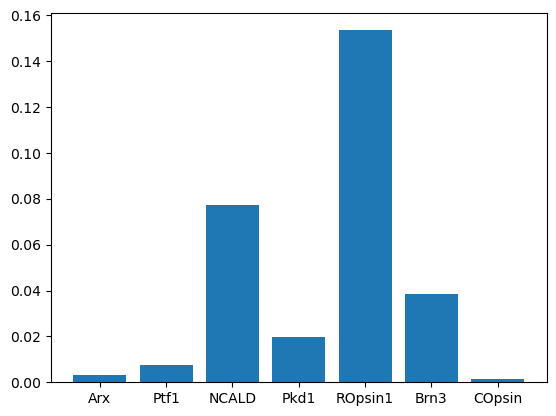

In [144]:
plt.bar(gene_list, nonzero_cluster[:, 0])

In [121]:
np.dot(e, nonzero_cluster) + np.dot(1 - e, 1 - nonzero_cluster)

array([[6.00582087, 6.06352276, 6.18106618, 6.06994245, 6.0731539 ,
        6.05879597, 6.03733766, 5.94330662, 6.10036316, 6.05390625,
        5.85783327, 5.93487993, 5.94852941, 5.95347744, 5.90620559,
        6.01586515, 6.05839416, 6.03313087, 6.06541524, 6.05936073,
        6.08257576, 6.07643814, 6.10660302, 6.07741935, 6.05300353,
        5.02060932, 5.88836773, 6.08140704, 6.07113821, 6.02906977,
        5.82264151, 6.04704301, 5.98866856, 6.09821429, 6.00303951,
        6.13271605, 6.00155763, 6.0642978 , 5.91636364, 6.95      ,
        5.78915663, 6.05906314, 6.04958678, 6.09090909, 6.00663717,
        6.09930716, 6.05626598, 6.07853403, 5.12064343, 6.1027027 ,
        6.21367521, 6.07905138, 6.056     , 6.07053942, 5.46666667,
        6.05365854, 6.01282051, 6.09271523, 6.11607143, 6.02272727,
        5.85074627, 5.77777778, 6.09433962, 5.41304348, 6.        ]])

In [23]:
expressed_prob = np.prod(nonzero_cluster[e.squeeze() > 0, :], axis=0)
nonexpressed_prob = np.prod((1 - nonzero_cluster)[(1 - e).squeeze() > 0, :], axis=0)
e_prob = expressed_prob * nonexpressed_prob

<BarContainer object of 65 artists>

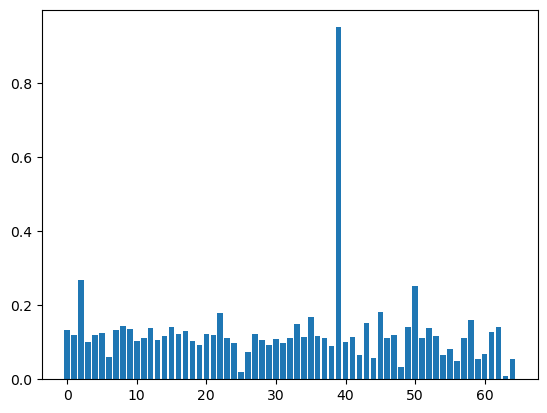

In [24]:
plt.bar(cluster_ids, e_prob)

In [134]:
e_prob.shape

(65,)

In [119]:
nonzero_cluster.sum(axis=1)

array([0.36236178, 0.64922204, 5.07195513, 1.80562969, 9.44936086,
       1.80257144, 0.05350037])

In [113]:
e

array([[0, 0, 0, 0, 1, 0, 0]])